In [734]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from xgboost import XGBClassifier
from xgboost import plot_importance
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.metrics import classification_report

In [735]:
X_train, y_train = joblib.load("../data/processed/train.joblib")

In [736]:
X_train.shape

(35641, 24)

In [737]:
X_train.corr()

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar
gender,1.000000,-0.289723,0.741430,0.573827,0.416373,0.145173,0.145634,-0.012318,-0.011479,0.169466,...,-0.303325,-0.042896,0.694032,0.019993,0.527067,0.100101,0.163520,0.236134,0.087462,0.058079
age,-0.289723,1.000000,-0.480494,-0.326235,-0.026055,-0.249966,-0.244006,0.203514,0.207381,0.133313,...,0.009047,0.039761,-0.261579,0.026624,-0.125419,0.030547,-0.062712,0.009125,-0.115508,-0.077936
height(cm),0.741430,-0.480494,1.000000,0.676254,0.378259,0.185492,0.188461,-0.082490,-0.080847,0.083330,...,-0.211258,-0.050189,0.533440,0.010179,0.403553,0.047923,0.125262,0.139727,0.081906,0.056408
weight(kg),0.573827,-0.326235,0.676254,1.000000,0.822854,0.127730,0.134584,-0.052036,-0.052427,0.269355,...,-0.356684,0.035858,0.484275,0.033001,0.340664,0.129001,0.244643,0.212010,0.076758,0.061945
waist(cm),0.416373,-0.026055,0.378259,0.822854,1.000000,0.026646,0.037719,0.021783,0.019874,0.320009,...,-0.372700,0.066633,0.375932,0.043011,0.237340,0.148724,0.244969,0.243646,0.044603,0.048946
eyesight(left),0.145173,-0.249966,0.185492,0.127730,0.026646,1.000000,0.449325,-0.061109,-0.073162,-0.033757,...,-0.016858,-0.007457,0.112052,-0.010206,0.074212,-0.012134,0.023285,0.005420,0.012271,0.023058
eyesight(right),0.145634,-0.244006,0.188461,0.134584,0.037719,0.449325,1.000000,-0.060629,-0.068485,-0.030734,...,-0.025012,-0.011225,0.114656,-0.015592,0.069943,-0.007887,0.027906,0.015691,0.017791,0.011643
hearing(left),-0.012318,0.203514,-0.082490,-0.052036,0.021783,-0.061109,-0.060629,1.000000,0.512932,0.056862,...,-0.016150,-0.016401,-0.028276,0.015488,-0.004129,0.008667,0.001121,0.010033,-0.014215,-0.035395
hearing(right),-0.011479,0.207381,-0.080847,-0.052427,0.019874,-0.073162,-0.068485,0.512932,1.000000,0.052991,...,-0.019444,-0.014420,-0.028311,0.020283,0.002862,0.005400,-0.001669,0.003921,-0.016877,-0.030071
systolic,0.169466,0.133313,0.083330,0.269355,0.320009,-0.033757,-0.030734,0.056862,0.052991,1.000000,...,-0.088004,0.010285,0.182598,0.040605,0.070922,0.088576,0.091283,0.166191,0.026264,0.006977


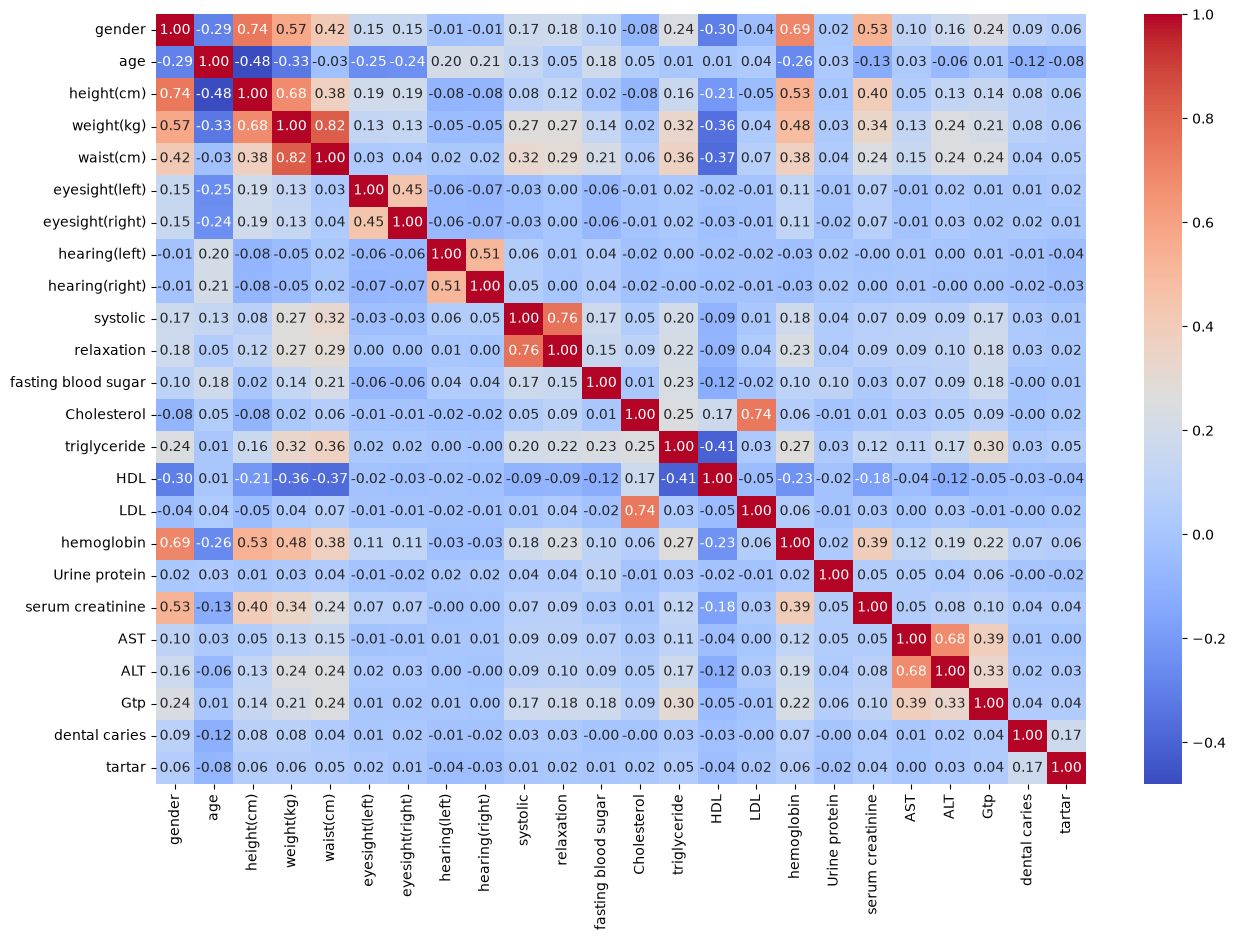

In [738]:
plt.figure(figsize=(15,10))
sns.heatmap(X_train.corr(), annot=True, cmap="coolwarm",fmt=".2f")
plt.show()

In [739]:
print(X_train[["hemoglobin", "gender", "height(cm)", "weight(kg)", "Gtp"]].corr()["hemoglobin"])

hemoglobin    1.000000
gender        0.694032
height(cm)    0.533440
weight(kg)    0.484275
Gtp           0.220483
Name: hemoglobin, dtype: float64


In [770]:
y_train.shape

(35641,)

In [848]:
%%time
#clf = XGBClassifier(n_estimators =300, learning_rate=0.02, max_depth=3, random_state=42)
clf = XGBClassifier(
    n_estimators = 250,
    learning_rate = 0.03,
    subsample = 0.8,        # proporciones de train tomadas aleatoriamente, para entrenar cada árbol
    colsample_bylevel=0.4,   # porciones de features tomadas aleatoriamente en cada nodo para entrenar cada árbol
    colsample_bytree=0.6,    # porciones de features tomadas aleatoriamente, para entrenar cada árbol
    max_depth=4,
    random_state=42
)

CPU times: total: 0 ns
Wall time: 127 μs


In [849]:
%%time
clf.fit(X_train, y_train)

CPU times: total: 3.75 s
Wall time: 1.03 s


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,0.4
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.6
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [850]:
%%time
train_pred = clf.predict(X_train)

CPU times: total: 203 ms
Wall time: 107 ms


In [851]:
print("Train")
print(classification_report(y_train, train_pred))

Train
              precision    recall  f1-score   support

           0       0.84      0.79      0.81     22560
           1       0.67      0.73      0.70     13081

    accuracy                           0.77     35641
   macro avg       0.75      0.76      0.76     35641
weighted avg       0.78      0.77      0.77     35641



<Figure size 1000x800 with 0 Axes>

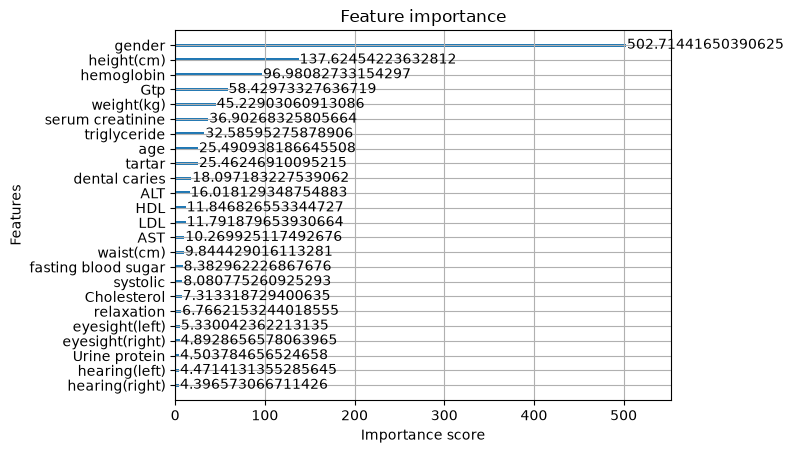

In [852]:
plt.figure(figsize=(10,8))
plot_importance(clf, max_num_features=27, importance_type="gain")
plt.show()

# Guardado de features y modelo no optimizado

In [853]:
joblib.dump(clf, "../models/mod_XGB.joblib")

['../models/mod_XGB.joblib']

In [854]:
joblib.dump(list(X_train.columns), "../models/features_XGB.joblib")

['../models/features_XGB.joblib']

# Optimización de hiperparámetros

In [855]:
xgb_model = XGBClassifier(objective='binary:logistic', eval_metric = "logloss", random_state=42)

In [856]:
xgb_model

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [857]:
param_dist = {
    "n_estimators": [50, 100, 150, 200, 250],
    "max_depth": [2,3,4,5],
    "learning_rate": [0.01, 0.02, 0.03, 0.04],
    "subsample": [0.6, 0.7, 0.8],
    "colsample_bylevel": [0.3, 0.4, 0.5],
    "colsample_bytree": [0.5, 0.6, 0.7],
}
"""
param_dist = {
    "n_estimators": [50, 100, 150, 200, 300],
    "max_depth": [4,5,6,7],
    "learning_rate": [0.02, 0.03, 0.04, 0.05],
    "subsample": [0.5, 0.6, 0.7],
    "colsample_bylevel": [0.4, 0.5, 0.6],
    "colsample_bytree": [0.5, 0.6, 0.7],
}

param_dist = {
    "n_estimators": [50, 100, 150, 200, 300],
    "max_depth": [3,4,5,6],
    "learning_rate": [0.02, 0.03, 0.04, 0.05],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.5, 0.6, 0.7],
    "colsample_bynode": [0.5, 0.6, 0.7],
}



param_dist = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [1,3,5],
    "learning_rate": [0.03, 0.04, 0.05],
    "subsample": [0.7, 0.8, 0.9]
}


param_dist = {
    "n_estimators": [400, 450, 500, 550],
    "max_depth": [1,3,5],
    "learning_rate": [0.02, 0.03, 0.05],
    "subsample": [0.7, 0.8, 0.9]
}


param_dist = {
    "n_estimators": [50, 100, 200, 500],
    "max_depth": [3,5,7],
    "learning_rate": [0.01, 0.05, 0.001],
    "subsample": [0.6, 0.8, 1]
}
"""

'\nparam_dist = {\n    "n_estimators": [50, 100, 150, 200, 300],\n    "max_depth": [4,5,6,7],\n    "learning_rate": [0.02, 0.03, 0.04, 0.05],\n    "subsample": [0.5, 0.6, 0.7],\n    "colsample_bylevel": [0.4, 0.5, 0.6],\n    "colsample_bytree": [0.5, 0.6, 0.7],\n}\n\nparam_dist = {\n    "n_estimators": [50, 100, 150, 200, 300],\n    "max_depth": [3,4,5,6],\n    "learning_rate": [0.02, 0.03, 0.04, 0.05],\n    "subsample": [0.7, 0.8, 0.9],\n    "colsample_bytree": [0.5, 0.6, 0.7],\n    "colsample_bynode": [0.5, 0.6, 0.7],\n}\n\n\n\nparam_dist = {\n    "n_estimators": [100, 200, 300, 400],\n    "max_depth": [1,3,5],\n    "learning_rate": [0.03, 0.04, 0.05],\n    "subsample": [0.7, 0.8, 0.9]\n}\n\n\nparam_dist = {\n    "n_estimators": [400, 450, 500, 550],\n    "max_depth": [1,3,5],\n    "learning_rate": [0.02, 0.03, 0.05],\n    "subsample": [0.7, 0.8, 0.9]\n}\n\n\nparam_dist = {\n    "n_estimators": [50, 100, 200, 500],\n    "max_depth": [3,5,7],\n    "learning_rate": [0.01, 0.05, 0.001],

In [858]:
fbeta_scorer = make_scorer(fbeta_score, beta=2)

In [859]:
model_search = RandomizedSearchCV(
    estimator = xgb_model,
    param_distributions=param_dist,
    n_iter = 30,
    scoring = fbeta_scorer,
    cv = 5,
    random_state=42,
    verbose=2,
    n_jobs=-1
)

In [860]:
model_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bylevel': [0.3, 0.4, ...], 'colsample_bytree': [0.5, 0.6, ...], 'learning_rate': [0.01, 0.02, ...], 'max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit

In [861]:
%%time
model_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
CPU times: total: 9.39 s
Wall time: 59.3 s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bylevel': [0.3, 0.4, ...], 'colsample_bytree': [0.5, 0.6, ...], 'learning_rate': [0.01, 0.02, ...], 'max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit

In [862]:
print(model_search.best_params_)

{'subsample': 0.6, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7, 'colsample_bylevel': 0.5}


In [863]:
best_model = model_search.best_estimator_

In [864]:
best_model

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,0.5
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [865]:
%%time
best_model.fit(X_train, y_train)

CPU times: total: 3.52 s
Wall time: 1.57 s


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,0.5
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [866]:
print("Train")
print(classification_report(y_train, train_pred))

Train
              precision    recall  f1-score   support

           0       0.84      0.79      0.81     22560
           1       0.67      0.73      0.70     13081

    accuracy                           0.77     35641
   macro avg       0.75      0.76      0.76     35641
weighted avg       0.78      0.77      0.77     35641



# Importancia relativa de atributos

<Figure size 1000x800 with 0 Axes>

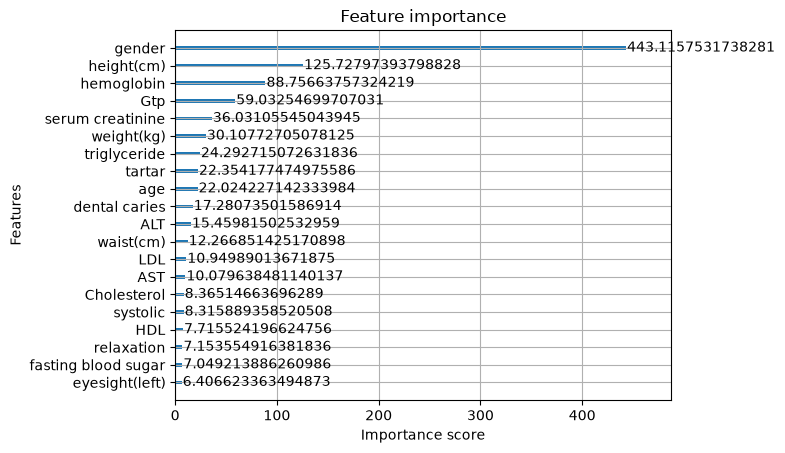

In [867]:
plt.figure(figsize=(10,8))
plot_importance(best_model, max_num_features=20, importance_type="gain")
plt.show()

# Guardado de features, umbral y modelo XGBoost

In [868]:
joblib.dump(best_model, "../models/mod_XGB_optimizado.joblib")

['../models/mod_XGB_optimizado.joblib']

In [869]:
joblib.dump(list(X_train.columns), "../models/features_XGB_optimizado.joblib")

['../models/features_XGB_optimizado.joblib']